In [13]:
import pandas as pd
import matplotlib.pyplot as plt

In [14]:

# === Load the CSV file ===
# If you have a file, replace this with pd.read_csv("your_file.csv")
csv_path = "exp_lr4.7e-3_step6_gamma0.808_epochs100_cls7_ch6_win1024_stride256_bs32_wd6.7e-5_015B.csv"
df = pd.read_csv(csv_path)

In [15]:

# Convert 'validation' to boolean if needed
df['validation'] = df['validation'].astype(bool)

# === Split into training and validation sets ===
df_train = df[df['validation'] == False]
df_val = df[df['validation'] == True]

In [16]:

# === Pivot the data for plotting ===
# Create pivoted dataframes where rows are epochs and columns are metrics
train_pivot = df_train.pivot(index='epoch', columns='metric', values='values')
val_pivot = df_val.pivot(index='epoch', columns='metric', values='values')

In [17]:

# === Convert values to float for plotting ===
train_pivot = train_pivot.astype(float)

# Keep the 'metrics.TEST_CONF' column unchanged
excluded_column = 'metrics.TEST_CONF'

# Convert all other columns to float
val_pivot.loc[:, val_pivot.columns != excluded_column] = val_pivot.loc[:, val_pivot.columns != excluded_column].astype(float)


In [18]:

# === Plot Train Accuracy vs Test Accuracy ===
def plot_metrics(train_pivot, val_pivot, train_metric, test_metric, train_label, test_label, y_label, title):
    plt.figure(figsize=(10, 5))
    plt.plot(train_pivot.index, train_pivot[train_metric], label=train_label, marker='o')
    plt.plot(val_pivot.index, val_pivot[test_metric], label=test_label, marker='o')
    plt.xlabel('Epoch')
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

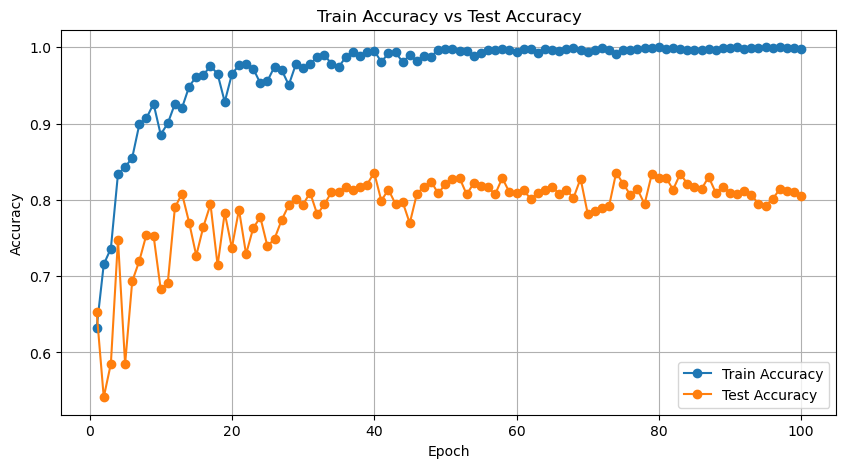

In [19]:
plot_metrics(
    train_pivot, 
    val_pivot, 
    'metrics.TRAIN_ACC', 
    'metrics.TEST_ACC',
    'Train Accuracy', 
    'Test Accuracy',
    'Accuracy',
    'Train Accuracy vs Test Accuracy'
)

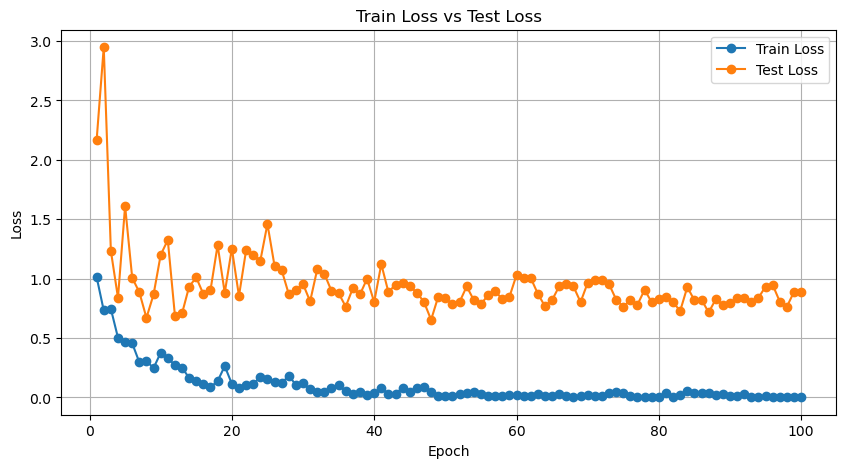

In [20]:
plot_metrics(
    train_pivot, 
    val_pivot, 
    'metrics.LOSS', 
    'metrics.LOSS',
    'Train Loss', 
    'Test Loss',
    'Loss',
    'Train Loss vs Test Loss'
)

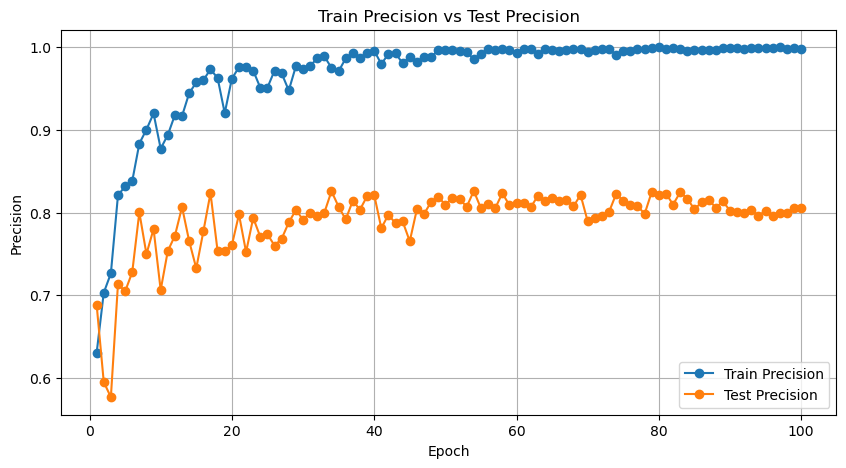

In [21]:
plot_metrics(
    train_pivot, 
    val_pivot, 
    'metrics.TRAIN_PREC', 
    'metrics.TEST_PREC',
    'Train Precision', 
    'Test Precision',
    'Precision',
    'Train Precision vs Test Precision'
)

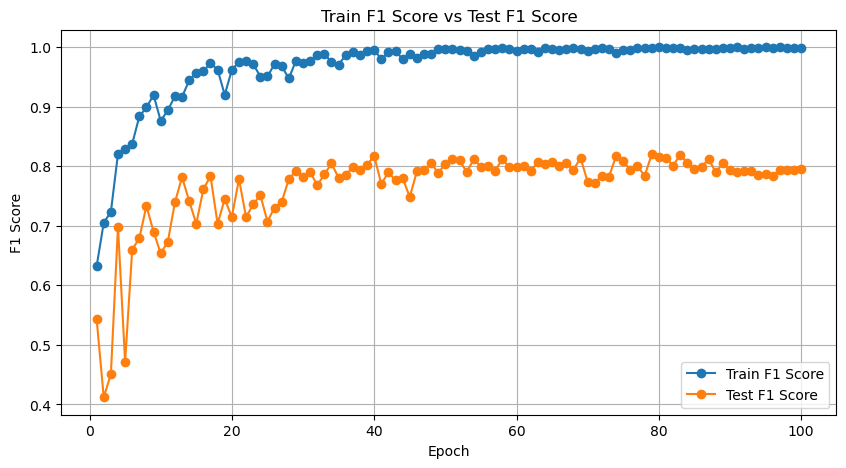

In [22]:
plot_metrics(
    train_pivot, 
    val_pivot, 
    'metrics.TRAIN_F1', 
    'metrics.TEST_F1',
    'Train F1 Score', 
    'Test F1 Score',
    'F1 Score',
    'Train F1 Score vs Test F1 Score'
)

In [23]:
max_index = val_pivot['metrics.TEST_ACC'].idxmax()
print(f"Bal. Accuracy: {val_pivot['metrics.TEST_ACC'][max_index]}\
      \nPrecision: {val_pivot['metrics.TEST_PREC'][max_index]}\
      \nF1 Score: {val_pivot['metrics.TEST_F1'][max_index]}")

Bal. Accuracy: 0.8357134478550682      
Precision: 0.821474337004005      
F1 Score: 0.8176302828323903


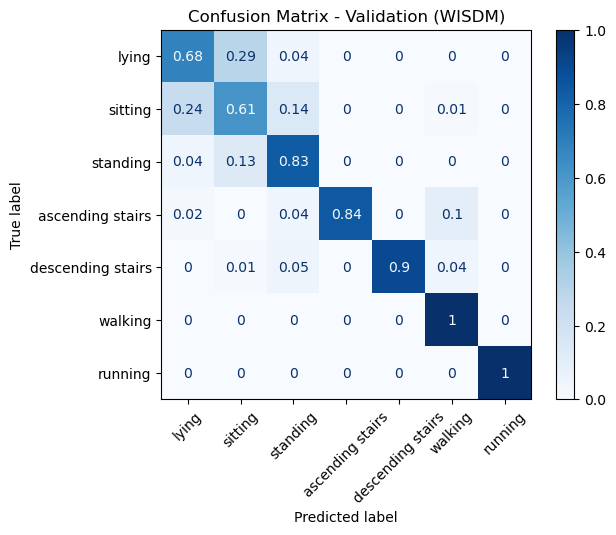

In [24]:
import numpy as np
import re
from sklearn.metrics import ConfusionMatrixDisplay

mapping = {'lying': 0,
 'sitting': 1,
 'standing': 2,
 'ascending stairs': 3,
 'descending stairs': 4,
 'walking': 5,
 'running': 6}

if 'metrics.TEST_CONF' in val_pivot.columns:
    conf_matrix_str = val_pivot['metrics.TEST_CONF'][max_index]
    
    if isinstance(conf_matrix_str, str):
        # Remove brackets to get flat array of numbers
        numbers_only = re.sub(r'[\[\]]', '', conf_matrix_str)
        
        # Parse into 1D array
        flat = np.fromstring(numbers_only, sep=' ')
        
        # Infer square matrix shape if needed (or use fixed shape like (7, 7))
        size = int(np.sqrt(len(flat)))
        conf_matrix = flat.reshape((size, size))
    else:
        conf_matrix = np.array(conf_matrix_str, dtype=float)

    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix.round(2), display_labels=mapping)
    disp.plot(cmap='Blues')
    plt.title('Confusion Matrix - Validation (WISDM)')
    plt.xticks(rotation=45)
    plt.show()
